In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATA = Path("../data")
df = pd.read_csv(DATA / "merged_school_dataset.csv")

numeric_features = [
    "fsm_pct_2024", "imd_score", "income_score", "employment_score",
    "health_score", "crime_score", "barriers_score", "living_env_score",
    "idaci_score", "adult_skills_score", "geo_barriers_score",
    "wider_barriers_score", "indoors_score", "outdoors_score",
    "p8_2023", "a8_2024",
]

# Rebuild the exact same split used in ann_a8.ipynb
df_a8 = df.loc[df["a8_2025"].notna()].copy()
X_raw = df_a8[numeric_features]
y_raw = df_a8["a8_2025"].values

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=SEED)

imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()
X_train = scaler.fit_transform(imputer.fit_transform(X_train_raw))
X_test  = scaler.transform(imputer.transform(X_test_raw))

y_mean, y_std = y_train.mean(), y_train.std()

# Rebuild the model and load trained weights
class A8ANN(nn.Module):
    def __init__(self, n_features=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 32),         nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(32, 1),
        )
    def forward(self, x): return self.net(x)

model = A8ANN()
model.load_state_dict(torch.load("../models/a8_ann.pt"))
model.eval()
print("Model loaded. Test shape:", X_test.shape)

C:\Users\npubu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model loaded. Test shape: (483, 16)


In [2]:
# SHAP needs a function that takes a numpy array and returns predictions
def predict_fn(X_numpy):
    with torch.no_grad():
        X_t = torch.FloatTensor(X_numpy)
        pred_scaled = model(X_t).numpy().ravel()
        pred = pred_scaled * y_std + y_mean   # de-standardise to A8 units
    return pred

# KernelExplainer works for any model but is slow — use a small background sample
# Background = reference set SHAP uses to compute baseline. 100 rows is plenty.
background = shap.sample(X_train, 100, random_state=SEED)

explainer = shap.KernelExplainer(predict_fn, background)
print("SHAP explainer created.")
print(f"Baseline (expected prediction): {explainer.expected_value:.2f}")

SHAP explainer created.
Baseline (expected prediction): 47.78


In [3]:
# Compute SHAP for a sample of test schools (full test set would take ~30 min)
# 100 schools gives representative patterns in about 3-5 minutes
n_explain = 100
X_explain = X_test[:n_explain]
shap_values = explainer.shap_values(X_explain, nsamples=100)

print(f"SHAP values shape: {shap_values.shape}")
# Should be (100, 16) — one row per school, one column per feature

100%|██████████| 100/100 [00:01<00:00, 66.80it/s]

SHAP values shape: (100, 16)


C:\Users\npubu\AppData\Local\Temp\ipykernel_22132\2855850661.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


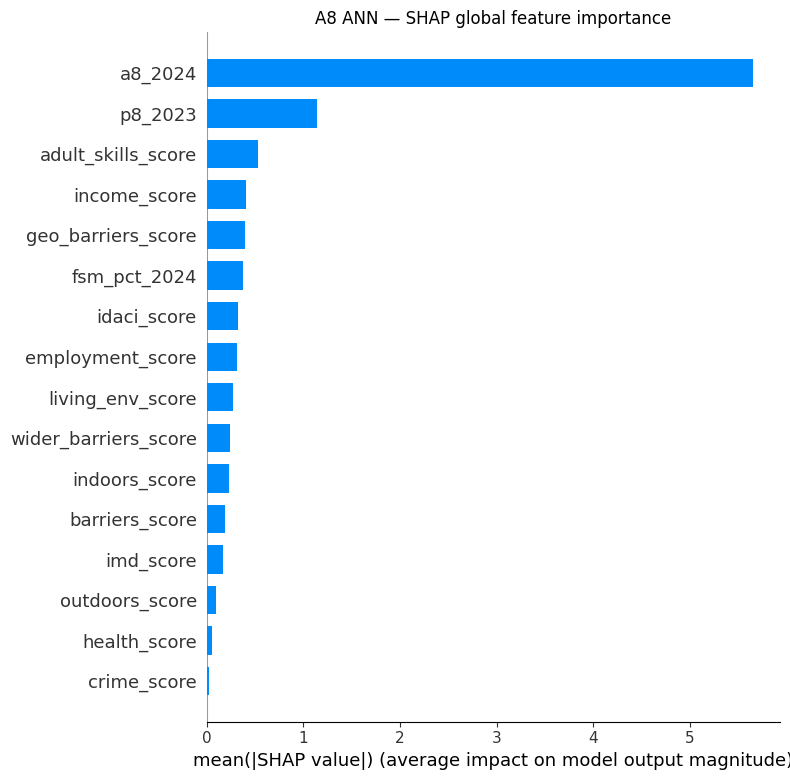

In [4]:
shap.summary_plot(
    shap_values, X_explain,
    feature_names=numeric_features,
    plot_type="bar",
    show=False,
)
plt.title("A8 ANN — SHAP global feature importance")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_a8_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\npubu\AppData\Local\Temp\ipykernel_22132\2457176142.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


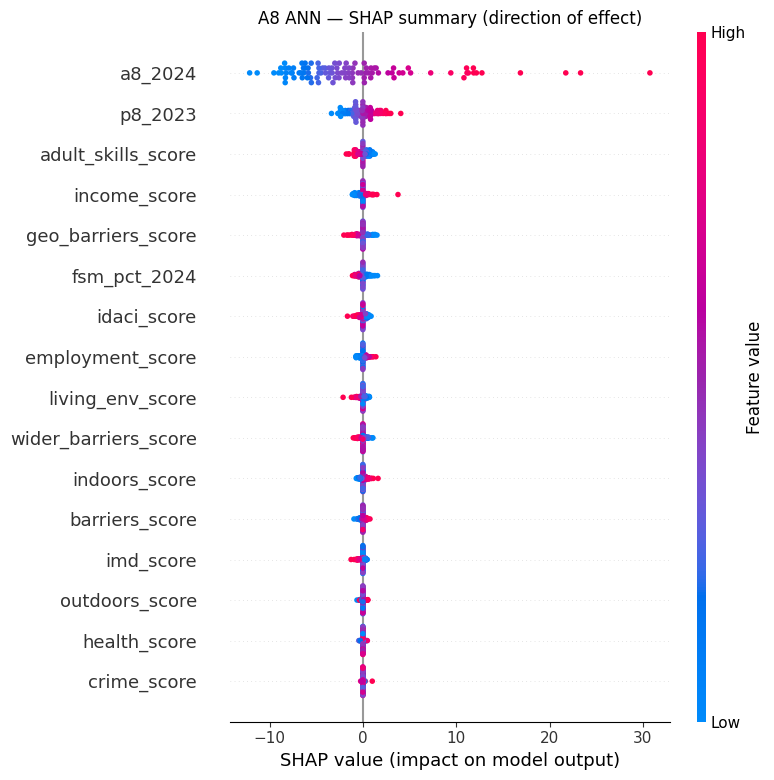

In [5]:
shap.summary_plot(
    shap_values, X_explain,
    feature_names=numeric_features,
    show=False,
)
plt.title("A8 ANN — SHAP summary (direction of effect)")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_a8_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

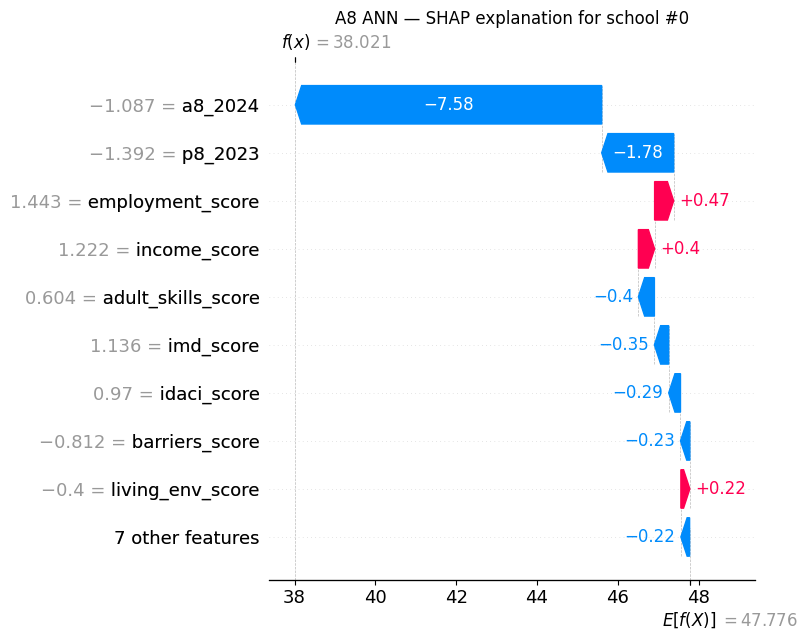

School #0:
  Actual A8:    37.9
  Predicted A8: 38.0
  Baseline:     47.78


In [6]:
# Pick an interesting school — e.g. one the model got wrong, or a low performer
# For now, just the first school in X_explain
school_idx = 0

# Reconstruct SHAP Explanation object for waterfall plot
shap_explanation = shap.Explanation(
    values=shap_values[school_idx],
    base_values=explainer.expected_value,
    data=X_explain[school_idx],
    feature_names=numeric_features,
)

shap.waterfall_plot(shap_explanation, show=False)
plt.title(f"A8 ANN — SHAP explanation for school #{school_idx}")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_a8_shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

# Print the actual numbers
actual = y_test[school_idx]
predicted = predict_fn(X_explain[school_idx:school_idx+1])[0]
print(f"School #{school_idx}:")
print(f"  Actual A8:    {actual:.1f}")
print(f"  Predicted A8: {predicted:.1f}")
print(f"  Baseline:     {explainer.expected_value:.2f}")

Correlation matrix of deprivation features:
                    fsm_pct_2024  imd_score  income_score  idaci_score  \
fsm_pct_2024                1.00       0.54          0.53         0.55   
imd_score                   0.54       1.00          0.96         0.90   
income_score                0.53       0.96          1.00         0.95   
idaci_score                 0.55       0.90          0.95         1.00   
adult_skills_score          0.47       0.86          0.85         0.81   

                    adult_skills_score  
fsm_pct_2024                      0.47  
imd_score                         0.86  
income_score                      0.85  
idaci_score                       0.81  
adult_skills_score                1.00  


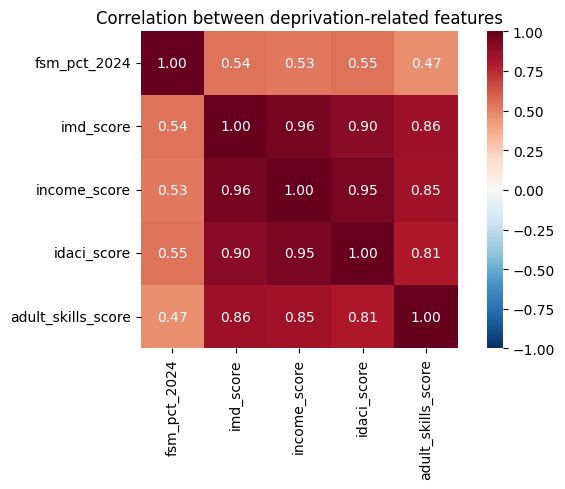

In [7]:
# Check correlation between the deprivation features
dep_features = ["fsm_pct_2024", "imd_score", "income_score",
                "idaci_score", "adult_skills_score"]
corr = pd.DataFrame(X_train, columns=numeric_features)[dep_features].corr()
print("Correlation matrix of deprivation features:")
print(corr.round(2))

# Plot it
import seaborn as sns
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            fmt=".2f", square=True)
plt.title("Correlation between deprivation-related features")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_a8_deprivation_correlations.png",
            dpi=150, bbox_inches="tight")
plt.show()